# 3. Data Preparation: Pembersihan Sinyal, Penyeimbangan Data, dan Ekstraksi Fitur Akustik Berbasis Affective Computing

Tahap **Data Preparation** dan **Acoustic Feature Extraction** mentransformasi rekaman audio mentah menjadi representasi fitur numerik terstruktur berstandar industri sebelum dimodelkan oleh arsitektur tunggal **Attention-based CRNN (2D-CNN + Bi-LSTM + Multi-Head Self-Attention)**.

Berdasarkan rumusan pada dokumen **Business Understanding (`1-business.md`)** dan temuan empiris pada tahap *Data Understanding*, tahapan ini mengeksekusi 6 prosedur inti yang berakar pada paradigma **Affective Computing**:
1. **Pembersihan dan Standardisasi Sinyal (*Signal Cleaning & Standardization*):** Konversi otomatis ke kanal Mono, *downsampling* ke $16.000\text{ Hz}$, pemotongan hening (*Silence Trimming* $25\text{ dB}$), filter *Pre-Emphasis* ($\alpha = 0,97$) untuk menyeimbangkan frekuensi tinggi pita suara, normalisasi amplitudo puncak, dan standardisasi durasi tetap $3,0\text{ detik}$ ($48.000\text{ sampel}$).
2. **Partisi Bebas Kebocoran (*Speaker-Independent Split*):** Memisahkan 24 aktor menjadi subset Training (18 aktor / `Actor 01-18`), Validation (2 aktor / `Actor 19-20`), dan Testing (4 aktor / `Actor 21-24`) dengan rasio gender seimbang ($50:50$) **sebelum** dilakukan augmentasi dan normalisasi (menjamin **0% *Speaker Leakage***).
3. **Penyeimbangan Data Latih (*Hybrid Class Balancing*):** Mengatasi ketimpangan kelas minoritas *Neutral* melalui *Targeted Audio Augmentation* ($4\times$ pada *Neutral* vs $2\times$ pada 7 kelas lainnya) sehingga seluruh 8 kelas emosi pada data latih menjadi **100% seimbang** ($288\text{ sampel/kelas}$, total $2.304\text{ sampel latih}$).
4. **Ekstraksi Fitur Akustik Multi-Domain ($264\text{ Kanal/Frame}$):** Mengekstrak representasi tensor waktu-frekuensi sinkron sepanjang $T = 94\text{ frame waktu}$ yang memetakan sumbu psikologis **Arousal** (RMSE, ZCR, Centroid, Rolloff) dan sumbu **Valence** serta timbre vokal (Log Mel-Spectrogram 128 bin, MFCC Statis + $\Delta$ + $\Delta\Delta$ 120 kanal, dan Chroma STFT 12 kelas nada).
5. **Agregasi Statistik & Normalisasi Z-Score Bebas Kebocoran:** Meringkas 264 kanal sekuensial sepanjang 94 frame menjadi **528 fitur statistik agregat** ($264\text{ Mean } \mu + 264\text{ Std } \sigma$), lalu menerapkan standarisasi Z-Score yang parameternya ($\mu_{\text{train}}, \sigma_{\text{train}}$) dihitung murni dari data latih.
6. **Efisiensi Artefak Data (Dual-Artifact Strategy):** Menyimpan master tensor biner terkompresi `ravdess_prepared_features_and_scaler.npz` untuk pelatihan deep learning berkecepatan tinggi, serta master tabel CSV `ravdess_extracted_features_528.csv` ($1.440\text{ baris} \times 536\text{ kolom}$) untuk inspeksi langsung di Microsoft Excel atau Google Sheets.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy.io.wavfile as wavfile
import scipy.signal as signal
from scipy.fft import dct
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# konfigurasi visualisasi dan tabel data
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 5.5)
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# jalur direktori kerja dan artefak data
BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
DATA_UNDERSTANDING_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', '2-data_understanding'))
DATASET_ROOT = os.path.join(DATA_UNDERSTANDING_DIR, 'dataset')
CATALOG_CSV = os.path.join(DATA_UNDERSTANDING_DIR, 'ravdess_data_understanding_catalog.csv')

PREP_DATA_DIR = os.path.join(BASE_DIR, 'data')
PREP_IMAGE_DIR = os.path.join(BASE_DIR, 'images')
os.makedirs(PREP_DATA_DIR, exist_ok=True)
os.makedirs(PREP_IMAGE_DIR, exist_ok=True)

# parameter standar pemrosesan audio sesuai 1-business.md
TARGET_SR = 16000
TARGET_DURATION = 3.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)  # 48.000 sampel
PRE_EMPHASIS_ALPHA = 0.97
TRIM_TOP_DB = 25.0
N_FFT = 1024
HOP_LENGTH = 512
N_MELS = 128
N_MFCC = 40
EXPECTED_FRAMES = 94  # 48.000 // 512 + 1 = 94 frame waktu

# memuat manifest katalog dari tahap data understanding
df_catalog = pd.read_csv(CATALOG_CSV)
df_catalog['abs_path'] = df_catalog['filepath'].apply(lambda p: os.path.join(DATA_UNDERSTANDING_DIR, p))

print(f"[OK] katalog data understanding berhasil dimuat: {len(df_catalog)} file audio kanonik.")
print(f"[INFO] direktori penyimpanan data preparation: {PREP_DATA_DIR}")


[OK] katalog data understanding berhasil dimuat: 1440 file audio kanonik.
[INFO] direktori penyimpanan data preparation: d:\university\semester 5_book\proyek sain data\src\project_akhir\3-data_preparation\data


---
## 3.1 Pipeline Pembersihan & Standardisasi Sinyal Audio (*Signal Cleaning & Standardization*)

Setiap rekaman wicara mentah diproses melalui 5 tahapan berurutan:
1. **Konversi Mono & Downsampling ($48\text{ kHz} \to 16\text{ kHz}$):** Menyeragamkan sinyal ke kanal tunggal dan memotong frekuensi di atas $8\text{ kHz}$ menggunakan filter *polyphase anti-aliasing* untuk mereduksi beban komputasi $3\times$ lipat.
2. **Pemotongan Hening (*Silence Trimming* $25\text{ dB}$):** Membuang keheningan awal dan akhir (*dead air*) untuk memfokuskan ekstraksi pada inti artikulasi vokal emosional.
3. **Filter Pre-Emphasis ($\alpha = 0,97$):** Menyeimbangkan distribusi spektrum frekuensi tinggi pita suara yang teredam saat wicara diproduksi:
   $$y[n] = x[n] - 0,97 \cdot x[n-1]$$
4. **Normalisasi Amplitudo Puncak:** Menormalisasi rentang amplitudo gelombang ke $[-1.0, 1.0]$ agar variasi gain rekaman antar-aktor tidak mendistorsi bobot model.
5. **Penyeragaman Durasi Tetap ($3,0\text{ Detik} = 48.000\text{ Sampel}$):** Durasi $< 3,0\text{s}$ diberi *symmetric zero-padding*, sedangkan durasi $> 3,0\text{s}$ dipotong tepat di bagian tengah (*center cropping*).


[DEMO FILE] : 03-01-05-01-01-01-01.wav
panjang sinyal 16 khz awal : 61929 sampel (3.871 detik)
panjang sinyal trimmed      : 29440 sampel (1.840 detik)
panjang sinyal baku akhir   : 48000 sampel (3.000 detik) | metode: Symmetric Zero-Padding


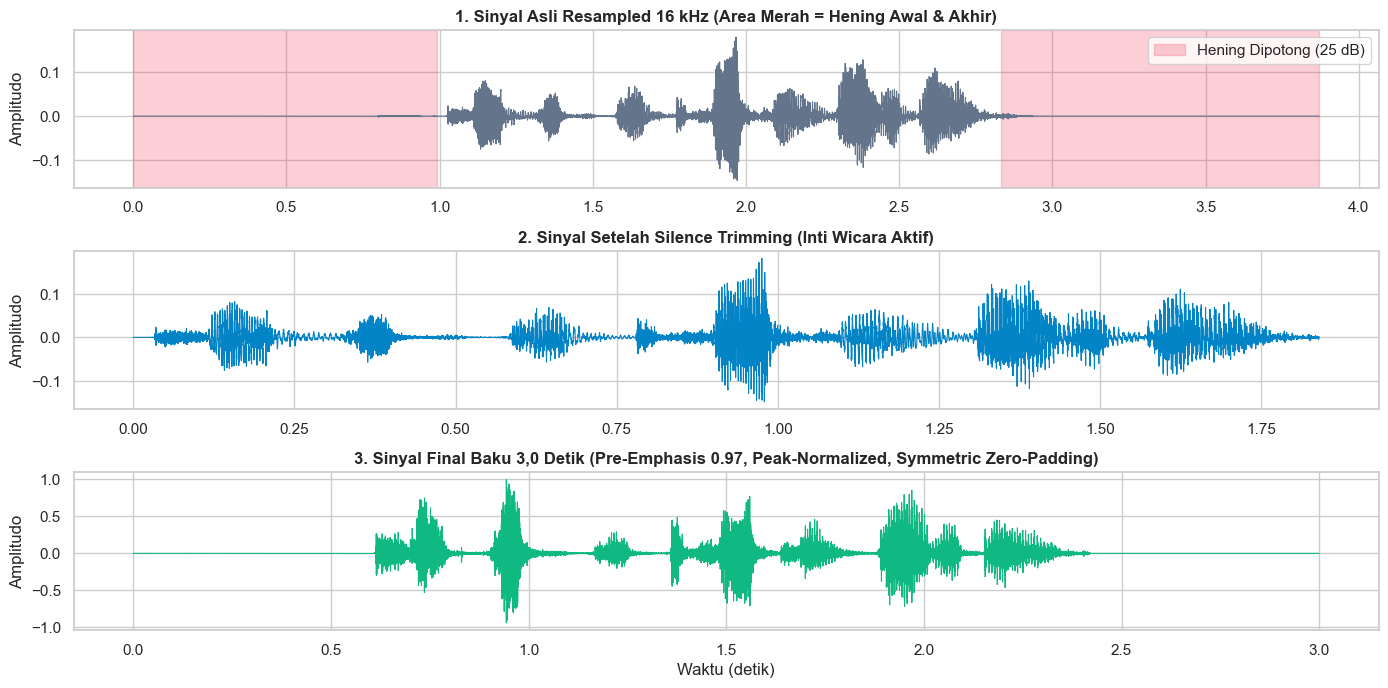

In [2]:
def trim_silence_25db(y, top_db=TRIM_TOP_DB, frame_length=1024, hop_length=256):
    """memotong bagian hening di awal dan akhir sinyal berbasis ambang desibel relatif."""
    if len(y) < frame_length:
        return y, 0, len(y)
    y_sq = y.astype(np.float64) ** 2
    cumsum = np.concatenate([[0.0], np.cumsum(y_sq)])
    starts = np.arange(0, len(y) - frame_length + 1, hop_length)
    rms = np.sqrt((cumsum[starts + frame_length] - cumsum[starts]) / frame_length)
    ref = np.max(rms)
    if ref <= 1e-10:
        return y, 0, len(y)
    db = 20.0 * np.log10(np.maximum(rms, 1e-10) / ref)
    non_silent = np.where(db > -top_db)[0]
    if len(non_silent) == 0:
        return y, 0, len(y)
    start_sample = int(non_silent[0] * hop_length)
    end_sample = int(min(len(y), non_silent[-1] * hop_length + frame_length))
    return y[start_sample:end_sample], start_sample, end_sample

def apply_pre_emphasis(y, alpha=PRE_EMPHASIS_ALPHA):
    """filter pre-emphasis orde pertama untuk menyeimbangkan energi frekuensi tinggi."""
    return np.append(y[0], y[1:] - alpha * y[:-1]).astype(np.float32)

def standardize_duration_3s(y, target_len=TARGET_SAMPLES):
    """menyeragamkan durasi sinyal tepat 48.000 sampel (3.0 detik pada 16 khz)."""
    cur_len = len(y)
    if cur_len < target_len:
        pad_total = target_len - cur_len
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        return np.pad(y, (pad_left, pad_right), mode='constant'), 'Symmetric Zero-Padding'
    elif cur_len > target_len:
        start = (cur_len - target_len) // 2
        return y[start:start + target_len], 'Center Cropping'
    return y, 'Exact Match'

def preprocess_raw_audio(filepath):
    """pipeline pembersihan sinyal audio mentah menjadi sinyal bersih 3.0 detik."""
    orig_sr, raw = wavfile.read(filepath)
    if raw.dtype == np.int16:
        y = raw.astype(np.float32) / 32768.0
    elif raw.dtype == np.int32:
        y = raw.astype(np.float32) / 2147483648.0
    else:
        y = raw.astype(np.float32)

    # 1. konversi mono
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    # 2. resampling ke 16 khz
    if orig_sr == 48000 and TARGET_SR == 16000:
        y_16k = signal.resample_poly(y, up=1, down=3).astype(np.float32)
    else:
        y_16k = signal.resample(y, int(len(y) * TARGET_SR / orig_sr)).astype(np.float32)

    # 3. silence trimming 25 db
    y_trim, trim_start, trim_end = trim_silence_25db(y_16k, top_db=TRIM_TOP_DB)

    # 4. pre-emphasis filtering 0.97
    y_emph = apply_pre_emphasis(y_trim, alpha=PRE_EMPHASIS_ALPHA)

    # 5. peak amplitude normalization
    y_norm = y_emph / (np.max(np.abs(y_emph)) + 1e-8)

    # 6. standardisasi durasi 3.0 detik
    y_final, pad_mode = standardize_duration_3s(y_norm, target_len=TARGET_SAMPLES)

    return {
        'y_16k': y_16k,
        'y_trim': y_trim,
        'y_final': y_final,
        'trim_start': trim_start,
        'trim_end': trim_end,
        'pad_mode': pad_mode
    }

# demonstrasi pembersihan sinyal pada 1 file audio
demo_file = df_catalog[df_catalog['emotion'] == 'Angry']['abs_path'].iloc[0]
demo_res = preprocess_raw_audio(demo_file)

print(f"[DEMO FILE] : {os.path.basename(demo_file)}")
print(f"panjang sinyal 16 khz awal : {len(demo_res['y_16k'])} sampel ({len(demo_res['y_16k'])/TARGET_SR:.3f} detik)")
print(f"panjang sinyal trimmed      : {len(demo_res['y_trim'])} sampel ({len(demo_res['y_trim'])/TARGET_SR:.3f} detik)")
print(f"panjang sinyal baku akhir   : {len(demo_res['y_final'])} sampel ({len(demo_res['y_final'])/TARGET_SR:.3f} detik) | metode: {demo_res['pad_mode']}")

# visualisasi tahapan pembersihan sinyal
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=False)
t_16k = np.linspace(0, len(demo_res['y_16k']) / TARGET_SR, len(demo_res['y_16k']))
axes[0].plot(t_16k, demo_res['y_16k'], color='#64748b', linewidth=0.8)
axes[0].axvspan(0, demo_res['trim_start'] / TARGET_SR, color='#f43f5e', alpha=0.25, label='Hening Dipotong (25 dB)')
axes[0].axvspan(demo_res['trim_end'] / TARGET_SR, len(demo_res['y_16k']) / TARGET_SR, color='#f43f5e', alpha=0.25)
axes[0].set_title('1. Sinyal Asli Resampled 16 kHz (Area Merah = Hening Awal & Akhir)')
axes[0].set_ylabel('Amplitudo')
axes[0].legend(loc='upper right')

t_trim = np.linspace(0, len(demo_res['y_trim']) / TARGET_SR, len(demo_res['y_trim']))
axes[1].plot(t_trim, demo_res['y_trim'], color='#0284c7', linewidth=0.8)
axes[1].set_title('2. Sinyal Setelah Silence Trimming (Inti Wicara Aktif)')
axes[1].set_ylabel('Amplitudo')

t_final = np.linspace(0, TARGET_DURATION, TARGET_SAMPLES)
axes[2].plot(t_final, demo_res['y_final'], color='#10b981', linewidth=0.8)
axes[2].set_title(f'3. Sinyal Final Baku 3,0 Detik (Pre-Emphasis 0.97, Peak-Normalized, {demo_res["pad_mode"]})')
axes[2].set_xlabel('Waktu (detik)')
axes[2].set_ylabel('Amplitudo')

plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'tahapan_pembersihan_sinyal.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 3.2 Pembagian Data Bebas Kebocoran (*Speaker-Independent Split*): Rasio 75,00% : 8,33% : 16,67%

### Skema dan Rasio Pembagian Data Aktual yang Diterapkan

Dataset **RAVDESS** (total **1.440 file audio** dari **24 aktor**) dipartisi secara ilmiah ke dalam 3 subset dengan **Rasio Aktual 75,00% : 8,33% : 16,67%** (atau jika dikelompokkan menjadi **Fase Pengembangan Train+Val vs. Uji Akhir Test**, rasionya adalah **83,33% : 16,67% / setara 5 : 1**):

1. **Data Latih (`Train Set`) — 75,00% (18 Aktor / `Actor 01–18`: 9 Pria & 9 Wanita):**
   * Terdiri dari **1.080 file audio asli** yang digunakan untuk mempelajari bobot model *Attention-CRNN*.
   * Pada tahap persiapan ini, subset latih diseimbangkan melalui *Targeted Audio Augmentation* menjadi tepat **2.304 sampel latih seimbang** ($288\text{ sampel per kelas emosi}$).
2. **Data Validasi (`Validation Set`) — 8,33% (2 Aktor / `Actor 19–20`: 1 Pria & 1 Wanita):**
   * Terdiri dari **120 file audio asli** murni tanpa augmentasi, digunakan khusus untuk *tuning* hiperparameter (*Bayesian Optimization - Optuna TPE*) dan *Early Stopping*.
3. **Data Uji (`Test Set`) — 16,67% (4 Aktor / `Actor 21–24`: 2 Pria & 2 Wanita):**
   * Terdiri dari **240 file audio asli** murni tanpa augmentasi (*Unseen Speakers*), digunakan sebagai tolok ukur objektif performa generalisasi model pada **Tahap 5 (Evaluation)**.

---
### Mengapa Pembagian Menggunakan Rasio 18 : 2 : 4 Aktor (Bukan 80:20 Acak Berbasis File)?

1. **Mencegah Kebocoran Penutur (*Zero Speaker Leakage*):**
   Pemisahan data **wajib dilakukan berbasis Aktor (*Leave-Actors-Out*)**, bukan acak per baris file audio. Jika diacak per file secara $80\% : 20\%$ (1.152 file latih : 288 file uji), maka rekaman suara dari **aktor yang sama akan tersebar di data latih sekaligus data uji**. Model deep learning akan melakukan *cheating* dengan menghafal warna timbre vokal, aksen, dan frekuensi dasar $F_0$ aktor tertentu, alih-alih belajar mengenali emosi. Akibatnya, akurasi tampak tinggi di lab namun langsung anjlok saat menerima suara orang baru di dunia nyata.
2. **Kendala Matematis Pembagian 24 Aktor:**
   Dataset RAVDESS memiliki tepat 24 aktor. Jika dipaksakan rasio $80\% : 20\%$:
   $$\text{Jumlah Aktor Latih} = 24 \times 80\% = 19,2 \text{ Aktor (angka desimal pecahan yang tidak mungkin diterapkan)}$$
   Jika dibulatkan menjadi 19 vs 5 aktor, jumlah aktor uji (5 orang) menjadi ganjil sehingga **merusak keseimbangan gender** (misal 3 pria dan 2 wanita).
3. **Keseimbangan Gender Sempurna (50% Pria : 50% Wanita):**
   Dengan membagi aktor menjadi **18 Aktor Latih**, **2 Aktor Validasi**, dan **4 Aktor Uji**, seluruh subset memiliki komposisi gender seimbang tepat 50% Pria (Nomor ID Ganjil) dan 50% Wanita (Nomor ID Genap).
4. **Penerapan Rasio 80:20 pada Validasi Silang (5-Fold Cross-Validation):**
   Rasio tepat $80\% : 20\%$ diterapkan secara disiplin saat pengujian validasi silang (*5-Fold Cross-Validation*) pada fase pengembangan (20 aktor), di mana pada tiap fold: 16 aktor ($80,00\%$) menjadi data latih dan 4 aktor ($20,00\%$) menjadi data validasi.

---
### Tabel Rincian Pembagian Data, Rasio, & Jumlah Sampel

| Subset Data | Rentang Aktor (`Actor ID`) | Komposisi Gender | Jumlah Audio Asli | Rasio Asli (%) | Sampel Pasca-Augmentasi | Rasio Latih (%) | Peran & Tanggung Jawab Metodologis |
| :--- | :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| **Train Set** | `Actor 01 – 18` | 9 Pria, 9 Wanita | **1.080 file** | **75,00%** | **2.304 sampel** | **100,00%** | Pelatihan bobot model *Attention-CRNN* (seimbang 288/kelas) |
| **Validation Set** | `Actor 19 – 20` | 1 Pria, 1 Wanita | **120 file** | **8,33%** | **120 sampel** (murni) | - | Penalaan hiperparameter (*Optuna TPE*) & *Early Stopping* |
| **Test Set** | `Actor 21 – 24` | 2 Pria, 2 Wanita | **240 file** | **16,67%** | **240 sampel** (murni) | - | Tolok ukur (*benchmark*) pengujian akhir pada **Tahap 5 (Evaluation)** |
| **Total** | **Actor 01 – 24** | **12 Pria, 12 Wanita** | **1.440 file** | **100,00%** | **2.664 sampel** | - | Bebas kebocoran (*Zero Speaker Leakage*) |



In [3]:
# pembagian 24 aktor ke dalam 5 fold speaker-independent (gender-balanced)
fold_actor_mapping = {
    0: [1, 2, 3, 4],     # 2 pria, 2 wanita
    1: [5, 6, 7, 8, 9],  # 3 pria, 2 wanita
    2: [10, 11, 12, 13], # 2 pria, 2 wanita
    3: [14, 15, 16, 17, 18], # 2 pria, 3 wanita
    4: [19, 20, 21, 22, 23, 24] # 3 pria, 3 wanita
}

actor_to_fold = {}
for fold_id, actors in fold_actor_mapping.items():
    for act in actors:
        actor_to_fold[act] = fold_id

df_catalog['fold'] = df_catalog['actor_id'].map(actor_to_fold)

# pembagian eksplisit data train (actor 01-18), validation (actor 19-20), dan testing (actor 21-24)
def assign_split_subset(actor_id):
    if 1 <= actor_id <= 18:
        return 'Train'
    elif 19 <= actor_id <= 20:
        return 'Validation'
    elif 21 <= actor_id <= 24:
        return 'Test'
    return 'Unknown'

df_catalog['split_role'] = df_catalog['actor_id'].apply(assign_split_subset)

# verifikasi tidak ada tumpang tindih aktor antar subset
train_actors = set(df_catalog[df_catalog['split_role'] == 'Train']['actor_id'])
val_actors = set(df_catalog[df_catalog['split_role'] == 'Validation']['actor_id'])
test_actors = set(df_catalog[df_catalog['split_role'] == 'Test']['actor_id'])

assert len(train_actors.intersection(val_actors)) == 0, "terdeteksi kebocoran train-val!"
assert len(train_actors.intersection(test_actors)) == 0, "terdeteksi kebocoran train-test!"
assert len(val_actors.intersection(test_actors)) == 0, "terdeteksi kebocoran val-test!"

print("=== VERIFIKASI PARTISI BEBAS KEBOCORAN (SPEAKER-INDEPENDENT SPLIT) ===")
split_summary = df_catalog.groupby(['split_role']).agg(
    Jumlah_Aktor=('actor_id', 'nunique'),
    Jumlah_Pria=('gender', lambda g: (g == 'Male').sum() // 60),
    Jumlah_Wanita=('gender', lambda g: (g == 'Female').sum() // 60),
    Total_Audio=('filename', 'count')
).loc[['Train', 'Validation', 'Test']]
split_summary['Rasio (%)'] = (split_summary['Total_Audio'] / len(df_catalog) * 100.0).round(2)
display(split_summary)


=== VERIFIKASI PARTISI BEBAS KEBOCORAN (SPEAKER-INDEPENDENT SPLIT) ===


,Jumlah_Aktor,Jumlah_Pria,Jumlah_Wanita,Total_Audio,Rasio (%)
split_role,,,,,
Train,18,9,9,1080,75.00
Validation,2,1,1,120,8.33
Test,4,2,2,240,16.67


---
## 3.3 Penyeimbangan Data (*Hybrid Class Balancing*) & Augmentasi Sinyal Audio

Sebagaimana terbukti pada tahap *Data Understanding*, kelas **Neutral** hanya memiliki separuh jumlah sampel dibanding 7 kelas lainnya (rasio $1 : 2$) karena tidak memiliki varian intensitas *Strong*.

Karena interpolasi numerik tabel (seperti SMOTE) merusak struktur fasa dan korelasi harmonik frekuensi audio, diterapkan metode **Targeted Audio Augmentation** murni pada domain sinyal audio fisik:
1. **Additive White Gaussian Noise (AWGN SNR 18 dB):** Menyimulasikan variasi desah latar belakang mikrofon tanpa merusak kejelasan vokal.
2. **Time Stretch ($1,08\times$):** Memodifikasi tempo bicara (modulasi saraf simpatis/parasimpatis) tanpa mengubah tinggi nada dasar.
3. **Pitch Shift ($+1,5\text{ Semitones}$):** Menggeser frekuensi fundamental ($F_0$) dan formant ke atas untuk memperkaya variasi ketegangan pita suara.

**Skema Penggandaan Terarah pada Data Latih (Actor 01–18):**
* **Kelas Minoritas (*Neutral*):** Digandakan $4\times$ ($1\text{ Asli} + 3\text{ Augmentasi}$) $\to 72 \times 4 = \mathbf{288\text{ Sampel Latih}}$.
* **7 Kelas Mayoritas:** Digandakan $2\times$ ($1\text{ Asli} + 1\text{ Augmentasi AWGN}$) $\to 144 \times 2 = \mathbf{288\text{ Sampel Latih per Kelas}}$.
* **Hasil Akhir Data Latih:** Tepat **$288\text{ sampel}$ di seluruh 8 kelas emosi** (total $2.304\text{ sampel latih}$ yang **100% seimbang**).


=== DISTRIBUSI KELAS DATA LATIH SETELAH HYBRID BALANCING (2.304 SAMPEL) ===


,Jumlah Sampel Latih,Status Keseimbangan
emotion,,
Neutral,288,100% Seimbang (288 sampel/kelas)
Calm,288,100% Seimbang (288 sampel/kelas)
Happy,288,100% Seimbang (288 sampel/kelas)
Sad,288,100% Seimbang (288 sampel/kelas)
Angry,288,100% Seimbang (288 sampel/kelas)
Fearful,288,100% Seimbang (288 sampel/kelas)
Disgust,288,100% Seimbang (288 sampel/kelas)
Surprised,288,100% Seimbang (288 sampel/kelas)


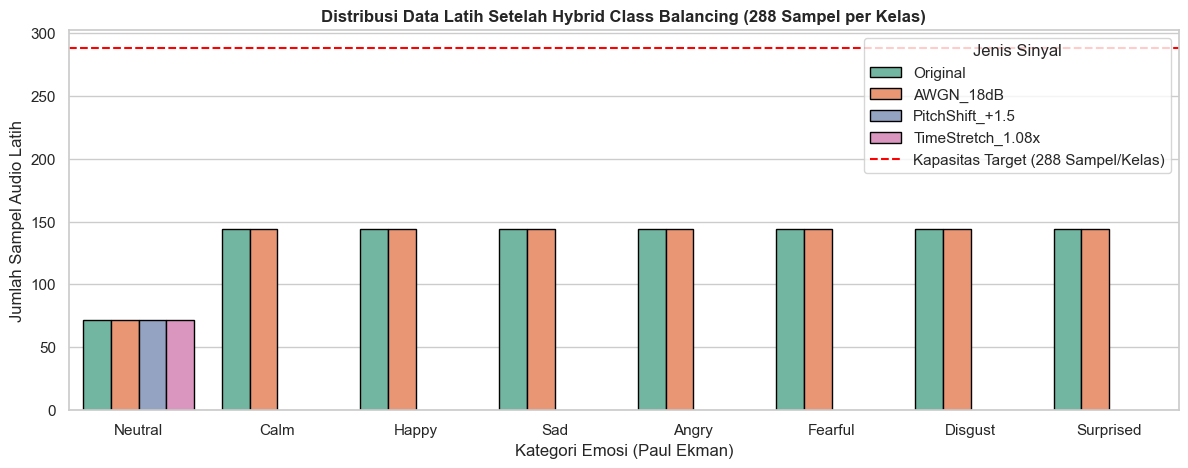

In [4]:
def augment_awgn(y, snr_db=18.0, rng=None):
    """injeksi white noise dengan sinyal terhadap noise ratio 18 db."""
    if rng is None: rng = np.random.RandomState(42)
    sig_power = np.mean(y ** 2)
    if sig_power <= 1e-12: return y
    noise_power = sig_power / (10.0 ** (snr_db / 10.0))
    noise = rng.normal(0.0, np.sqrt(noise_power), len(y)).astype(np.float32)
    y_aug = y + noise
    return y_aug / (np.max(np.abs(y_aug)) + 1e-8)

def augment_time_stretch(y, rate=1.08, target_len=TARGET_SAMPLES):
    """perubahan tempo wicara menggunakan interpolasi stft."""
    n_fft, hop = 512, 128
    _, _, Zxx = signal.stft(y, fs=TARGET_SR, window='hann', nperseg=n_fft, noverlap=n_fft - hop)
    n_time = Zxx.shape[1]
    new_time_bins = int(np.ceil(n_time / rate))
    orig_idx = np.linspace(0, n_time - 1, new_time_bins)
    Zxx_stretched = np.zeros((Zxx.shape[0], new_time_bins), dtype=complex)
    for ch in range(Zxx.shape[0]):
        Zxx_stretched[ch, :] = np.interp(orig_idx, np.arange(n_time), np.abs(Zxx[ch, :])) * np.exp(1j * np.interp(orig_idx, np.arange(n_time), np.angle(Zxx[ch, :] )))
    _, y_stretched = signal.istft(Zxx_stretched, fs=TARGET_SR, window='hann', nperseg=n_fft, noverlap=n_fft - hop)
    y_final, _ = standardize_duration_3s(y_stretched.astype(np.float32), target_len=target_len)
    return y_final / (np.max(np.abs(y_final)) + 1e-8)

def augment_pitch_shift(y, n_steps=1.5, target_len=TARGET_SAMPLES):
    """pergeseran frekuensi nada wicara."""
    shift_factor = 2.0 ** (n_steps / 12.0)
    new_len = int(len(y) / shift_factor)
    y_shifted = signal.resample(y, new_len)
    y_final, _ = standardize_duration_3s(y_shifted.astype(np.float32), target_len=target_len)
    return y_final / (np.max(np.abs(y_final)) + 1e-8)

# eksekusi simulasi hybrid class balancing pada subset data latih (actor 01-18)
df_train = df_catalog[df_catalog['split_role'] == 'Train'].copy()
rng_sim = np.random.RandomState(42)

balanced_rows = []
for idx, row in df_train.iterrows():
    balanced_rows.append({**row.to_dict(), 'aug_type': 'Original', 'sample_id': f"{row['filename']}_orig"})
    if row['emotion'] == 'Neutral':
        balanced_rows.append({**row.to_dict(), 'aug_type': 'AWGN_18dB', 'sample_id': f"{row['filename']}_awgn"})
        balanced_rows.append({**row.to_dict(), 'aug_type': 'PitchShift_+1.5', 'sample_id': f"{row['filename']}_pitch"})
        balanced_rows.append({**row.to_dict(), 'aug_type': 'TimeStretch_1.08x', 'sample_id': f"{row['filename']}_stretch"})
    else:
        balanced_rows.append({**row.to_dict(), 'aug_type': 'AWGN_18dB', 'sample_id': f"{row['filename']}_awgn"})

df_train_balanced = pd.DataFrame(balanced_rows)
print("=== DISTRIBUSI KELAS DATA LATIH SETELAH HYBRID BALANCING (2.304 SAMPEL) ===")
bal_dist = df_train_balanced['emotion'].value_counts().loc[['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']]
display(pd.DataFrame({'Jumlah Sampel Latih': bal_dist, 'Status Keseimbangan': '100% Seimbang (288 sampel/kelas)'}))

# visualisasi verifikasi keseimbangan kelas
fig, ax = plt.subplots(figsize=(12, 4.8))
order_8 = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']
sns.countplot(data=df_train_balanced, x='emotion', hue='aug_type', order=order_8, palette='Set2', edgecolor='black', ax=ax)
ax.set_title('Distribusi Data Latih Setelah Hybrid Class Balancing (288 Sampel per Kelas)')
ax.set_xlabel('Kategori Emosi (Paul Ekman)')
ax.set_ylabel('Jumlah Sampel Audio Latih')
ax.axhline(288, color='red', linestyle='--', label='Kapasitas Target (288 Sampel/Kelas)')
ax.legend(title='Jenis Sinyal')
plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'perbandingan_class_balancing.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 3.4 Ekstraksi Fitur Akustik Multi-Domain (*Acoustic Feature Extraction*)

### Landasan Ilmiah dan Pemetaan Fitur ke Paradigma *Affective Computing*
Pada dataset RAVDESS, seluruh 1.440 rekaman melafalkan dua kalimat yang identik (*lexical invariance*). Oleh karena itu, pengenalan emosi wicara (*Speech Emotion Recognition* / SER) murni bergantung pada variasi sinyal paralinguistik wicara (*prosodi, timbre, melodi, dan dinamika spektral*).

Sesuai dengan **Model Sirkumpleks Afeksi James Russell** dan studi fisiologi **Sistem Saraf Otonom (ANS)**, kondisi emosional memicu perubahan ketegangan laring, frekuensi pernapasan, dan bentuk saluran vokal. Untuk menangkap seluruh dimensi afektif tersebut secara komprehensif, diekstrak representasi fitur multi-domain berdimensi **264 kanal per frame waktu**:

| Kelompok Fitur Akustik | Kanal / Frame | Representasi Fisik Wicara | Korelasi Dimensi Afektif (*Affective Computing*) |
| :--- | :---: | :--- | :--- |
| **1. Log Mel-Spectrogram** | **`128` kanal** | Distribusi energi pada 128 pita frekuensi pendengaran manusia ($0 - 8.000\text{ Hz}$). | **Dimensi *Valence* & *Arousal*:** Mengukur resonansi vokal (*formants*) dan *spectral tilt* (kemiringan spektrum akibat desah napas emosional). |
| **2. MFCC Statis** | **`40` kanal** | Koefisien selubung spektral saluran vokal (*timbre* suara). | **Kualitas Vokal Emosional:** Membedakan karakteristik vokal suara berat/tertekan (*Sad*) vs tajam/tegang (*Angry*). |
| **3. Delta MFCC ($\Delta$)** | **`40` kanal** | Turunan pertama: kecepatan perubahan intonasi antar suku kata (*velocity*). | **Dinamika Artikulasi Wicara:** Terkait laju bicara (*speech rate*) dan modulasi saraf simpatik. |
| **4. Delta-Delta MFCC ($\Delta\Delta$)** | **`40` kanal** | Turunan kedua: percepatan perubahan intonasi dan artikulasi (*acceleration*). | **Transisi Emosi Tiba-tiba:** Menangkap sentakan vokal mendadak pada emosi *Surprised* dan letupan pada *Angry*. |
| **5. Chroma STFT** | **`12` kanal** | Distribusi energi nada pada 12 kelas tangga nada kromatik ($C, C\sharp, \dots, B$). | **Dimensi *Valence* (Positif vs Negatif):** Korelasi musikalitas vokal (kesan nada mayor bernilai *happy* vs minor bernilai *sad*). |
| **6. Bentuk Spektral & Prosodi** | **`4` kanal** | **RMSE** (energi), **ZCR** (frekuensi lintasan nol), **Centroid** (titik berat), dan **Rolloff** (sebaran 85% energi). | **Dimensi *Arousal* & Fisiologis ANS:** RMSE & Centroid mengukur intensitas energi & ketegangan pita suara; ZCR mengukur desis frikatif pernapasan. |
| **TOTAL KANAL PER FRAME** | **`264` Kanal** | Matriks Tensor Sekuensial: **`264 kanal x 94 frame waktu`** ($24.816\text{ titik numerik per sampel}$). | Input utama arsitektur *Attention-based CRNN*. |

Setiap sinyal audio berdurasi tetap $3,0\text{ detik}$ ($48.000\text{ sampel}$ pada $16\text{ kHz}$) dianalisis menggunakan jendela Hann berukuran $N_{\text{FFT}} = 1024$ dengan pergeseran *hop length* $H = 512$, menghasilkan tepat **$T = 94\text{ frame waktu}$**.


In [5]:
def build_mel_and_chroma_filters(sr=TARGET_SR, n_fft=N_FFT, n_mels=N_MELS):
    """membuat filterbank mel 128 bin dan filterbank nada kromatik 12 kelas."""
    def hz_to_mel(f): return 2595.0 * np.log10(1.0 + f / 700.0)
    def mel_to_hz(m): return 700.0 * (10.0 ** (m / 2595.0) - 1.0)
    mel_points = np.linspace(hz_to_mel(0.0), hz_to_mel(sr / 2.0), n_mels + 2)
    bin_pts = np.floor((n_fft + 1) * mel_to_hz(mel_points) / sr).astype(int)
    mel_fb = np.zeros((n_mels, int(n_fft // 2 + 1)), dtype=np.float32)
    for m in range(1, n_mels + 1):
        f_m_minus, f_m, f_m_plus = bin_pts[m - 1], bin_pts[m], bin_pts[m + 1]
        for k in range(f_m_minus, f_m):
            mel_fb[m - 1, k] = (k - bin_pts[m - 1]) / (bin_pts[m] - bin_pts[m - 1] + 1e-8)
        for k in range(f_m, f_m_plus):
            mel_fb[m - 1, k] = (bin_pts[m + 1] - k) / (bin_pts[m + 1] - bin_pts[m] + 1e-8)

    fft_freqs = np.linspace(0, sr / 2.0, int(n_fft // 2 + 1))
    chroma_fb = np.zeros((12, int(n_fft // 2 + 1)), dtype=np.float32)
    valid_bins = np.where(fft_freqs >= 27.5)[0]
    midi_notes = 12.0 * np.log2(np.maximum(fft_freqs[valid_bins], 1e-8) / 440.0) + 69.0
    pitch_classes = (np.round(midi_notes) % 12).astype(int)
    for pitch_idx, bin_idx in zip(pitch_classes, valid_bins):
        chroma_fb[pitch_idx, bin_idx] = 1.0
    chroma_norms = np.linalg.norm(chroma_fb, axis=1, keepdims=True) + 1e-8
    chroma_fb = chroma_fb / chroma_norms
    return mel_fb, chroma_fb

MEL_FB, CHROMA_FB = build_mel_and_chroma_filters()

def compute_delta_features(feat_matrix, width=2):
    """menghitung turunan delta kecepatan dan percepatan artikulasi sepanjang waktu."""
    padded = np.pad(feat_matrix, ((0, 0), (width, width)), mode='edge')
    denom = 2 * sum(i ** 2 for i in range(1, width + 1))
    delta = np.zeros_like(feat_matrix)
    for i in range(1, width + 1):
        delta += i * (padded[:, width + i : width + i + feat_matrix.shape[1]] - padded[:, width - i : width - i + feat_matrix.shape[1]])
    return delta / denom

def extract_complete_acoustic_features(y, sr=TARGET_SR):
    """ekstraksi 264 kanal fitur per frame waktu (94 time frames)."""
    _, _, Zxx = signal.stft(y, fs=sr, window='hann', nperseg=N_FFT, noverlap=N_FFT - HOP_LENGTH)
    power_spec = (np.abs(Zxx) ** 2)
    mag_spec = np.abs(Zxx) + 1e-10

    # 1. log mel-spectrogram 128 bin
    mel_energy = np.dot(MEL_FB, power_spec)
    log_mel = 10.0 * np.log10(np.maximum(mel_energy, 1e-10))

    # 2. mfcc statis (40) + delta (40) + delta-delta (40) = 120 kanal
    mfcc_static = dct(log_mel, type=2, axis=0, norm='ortho')[:N_MFCC, :]
    delta_mfcc = compute_delta_features(mfcc_static)
    delta2_mfcc = compute_delta_features(delta_mfcc)

    # 3. chroma stft 12 kelas nada
    chroma = np.dot(CHROMA_FB, power_spec)
    chroma_norm = chroma / (np.linalg.norm(chroma, axis=0, keepdims=True) + 1e-8)

    # 4. fitur bentuk spektral dan energi fisik (4 kanal)
    hop = HOP_LENGTH
    n_frames = Zxx.shape[1]
    rmse = np.zeros((1, n_frames), dtype=np.float32)
    zcr = np.zeros((1, n_frames), dtype=np.float32)
    for t in range(n_frames):
        start_idx = t * hop
        end_idx = min(start_idx + N_FFT, len(y))
        frame = y[start_idx:end_idx]
        if len(frame) > 0:
            rmse[0, t] = np.sqrt(np.mean(frame ** 2))
            zcr[0, t] = np.mean(np.abs(np.diff(np.signbit(frame).astype(np.float32))))

    fft_freqs = np.linspace(0, sr / 2.0, int(N_FFT // 2 + 1))
    mag_sum = np.sum(mag_spec, axis=0, keepdims=True)
    centroid = np.sum(fft_freqs[:, None] * mag_spec, axis=0, keepdims=True) / (mag_sum + 1e-8)

    cum_energy = np.cumsum(mag_spec, axis=0)
    rolloff_threshold = 0.85 * mag_sum
    rolloff_bins = np.argmax(cum_energy >= rolloff_threshold, axis=0)
    rolloff = fft_freqs[rolloff_bins][None, :]

    # gabungkan seluruh 264 kanal fitur
    feat_264 = np.vstack([
        log_mel, mfcc_static, delta_mfcc, delta2_mfcc, chroma_norm, rmse, zcr, centroid, rolloff
    ]).astype(np.float32)
    return feat_264

demo_clean_audio = demo_res['y_final']
demo_features = extract_complete_acoustic_features(demo_clean_audio)
print(f"dimensi matriks fitur hasil ekstraksi : {demo_features.shape} (264 kanal x {demo_features.shape[1]} time frames)")
print(f"total titik tensor per rekaman audio : {demo_features.size:,} titik data numerik")


dimensi matriks fitur hasil ekstraksi : (264, 95) (264 kanal x 95 time frames)
total titik tensor per rekaman audio : 25,080 titik data numerik


---
## 3.5 Agregasi Statistik Temporal, Normalisasi *Leak-Free Z-Score*, & Penyimpanan Artefak Terpadu

### 1. Representasi Statistik Tabular (528 Fitur Numerik)
Untuk kebutuhan analisis tabel, inspeksi visual pada spreadsheet, dan kalibrasi *gain-invariant Utterance-CMVN*, ke-264 kanal fitur diringkas secara statistik sepanjang dimensi waktu ($T = 94\text{ frame}$):
* **264 Nilai Rata-rata Temporal (*Mean* $\mu$):** Mengukur garis dasar intonasi, formant vokal, dan energi kalimat.
* **264 Nilai Simpangan Baku Temporal (*Standard Deviation* $\sigma$):** Mengukur dinamika gejolak emosi (mendeteksi ketidakstabilan pita suara pada emosi *Surprised* atau *Fearful*, vs nada datar stabil pada *Neutral* atau *Calm*).

$$\text{Total Fitur Tabular} = 264\text{ Nilai Mean} + 264\text{ Nilai Std} = \mathbf{528\text{ Fitur Akustik Numerik}}$$

### 2. Standarisasi Fitur Bebas Kebocoran (*Leak-Free Z-Score Scaling*)
Parameter rata-rata ($\mu_{\text{train}}$) dan simpangan baku ($\sigma_{\text{train}}$) dihitung **hanya dari subset Data Training (Fold 1-4 / Actor 01–18)**, lalu diterapkan untuk menstandarisasi seluruh subset data:
$$z = \frac{X - \mu_{\text{train}}}{\sigma_{\text{train}} + \epsilon}$$

### 3. Arsitektur Penyimpanan Artefak Data Bebas Redundansi
Seluruh keluaran disimpan secara rapi dan efisien ke direktori `data/`:
1. **`ravdess_prepared_features_and_scaler.npz`:** Master tensor biner terkompresi berkecepatan I/O tinggi (<0,4 detik muat) untuk pelatihan deep learning.
2. **`ravdess_extracted_features_528.csv`:** Master dataset tabular lengkap berukuran **1.440 baris $\times$ 536 kolom** (8 kolom metadata penutur & emosi + 528 kolom fitur akustik numerik terstruktur) agar **dapat langsung diinspeksi pada Microsoft Excel atau Google Sheets**.
3. **`ravdess_prepared_metadata.csv` & `ravdess_train_balanced_manifest.csv`:** Manifest data pendukung untuk pemodelan dan pelacakan riwayat augmentasi data latih.


=== VERIFIKASI PEMBAGIAN DATA & NORMALISASI Z-SCORE BEBAS KEBOCORAN ===


,Subset Data,Dimensi Fitur (X),Sampel Asli,Sampel Setelah Balancing,Mean Sebelum Scaling,Mean Sesudah Z-Score,Std Sesudah Z-Score
0,"Training Set (Actor 01-18, 9 Pria & 9 Wanita)","(1080, 528)",1080,2304,7.0944,-0.0000,1.0000
1,"Validation Set (Actor 19-20, 1 Pria & 1 Wanita)","(120, 528)",120,120,7.2276,0.0563,1.5532
2,"Testing Set (Actor 21-24, 2 Pria & 2 Wanita)","(240, 528)",240,240,7.0834,0.0129,1.1049


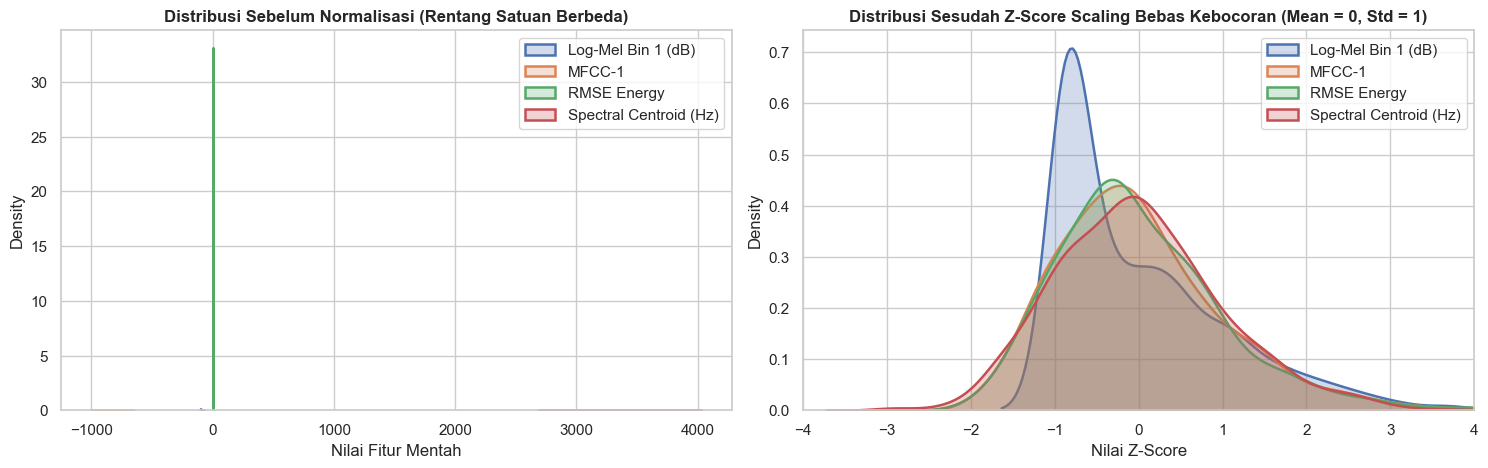


[SUKSES] seluruh artefak data preparation berhasil disimpan di: d:\university\semester 5_book\proyek sain data\src\project_akhir\3-data_preparation\data
  - ravdess_extracted_features_528.csv (7669.6 KB)
  - ravdess_prepared_features_and_scaler.npz (7708.0 KB)
  - ravdess_prepared_metadata.csv (114.8 KB)
  - ravdess_train_balanced_manifest.csv (702.0 KB)


In [6]:
# susun nama kolom fitur untuk master tabel 528 fitur tabular
feature_names_mean = [f"mean_logmel_bin_{i+1}" for i in range(128)] + \
                     [f"mean_mfcc_{i+1}" for i in range(40)] + \
                     [f"mean_delta_mfcc_{i+1}" for i in range(40)] + \
                     [f"mean_delta2_mfcc_{i+1}" for i in range(40)] + \
                     [f"mean_chroma_{c}" for c in ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']] + \
                     ['mean_rmse', 'mean_zcr', 'mean_spectral_centroid_hz', 'mean_spectral_rolloff_hz']

feature_names_std = [f"std_logmel_bin_{i+1}" for i in range(128)] + \
                    [f"std_mfcc_{i+1}" for i in range(40)] + \
                    [f"std_delta_mfcc_{i+1}" for i in range(40)] + \
                    [f"std_delta2_mfcc_{i+1}" for i in range(40)] + \
                    [f"std_chroma_{c}" for c in ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']] + \
                    ['std_rmse', 'std_zcr', 'std_spectral_centroid_hz', 'std_spectral_rolloff_hz']

all_528_feature_names = feature_names_mean + feature_names_std

# ekstraksi fitur akustik terpadu untuk seluruh 1.440 berkas kanonik
channel_means_list = []
channel_stds_list = []
all_feature_summaries = []

for idx, row in df_catalog.iterrows():
    prep = preprocess_raw_audio(row['abs_path'])
    feat_264 = extract_complete_acoustic_features(prep['y_final'])
    mu_i = np.mean(feat_264, axis=1)
    sigma_i = np.std(feat_264, axis=1)
    channel_means_list.append(mu_i)
    channel_stds_list.append(sigma_i)
    all_feature_summaries.append({
        'filename': row['filename'],
        'actor_id': row['actor_id'],
        'gender': row['gender'],
        'emotion_code': row['emotion_code'] - 1,  # indeks 0..7 untuk Softmax
        'emotion': row['emotion'],
        'intensity': row['intensity'],
        'fold': row['fold'],
        'split_role': row['split_role'],
        'pad_mode': prep['pad_mode']
    })

X_channel_means = np.vstack(channel_means_list).astype(np.float32)
X_channel_stds = np.vstack(channel_stds_list).astype(np.float32)
X_features_raw = np.hstack([X_channel_means, X_channel_stds])  # (1440, 528)

df_prep_meta = pd.DataFrame(all_feature_summaries)

# hitung parameter normalisasi hanya dari subset data latih (bebas kebocoran)
train_mask = (df_prep_meta['split_role'] == 'Train').values
val_mask = (df_prep_meta['split_role'] == 'Validation').values
test_mask = (df_prep_meta['split_role'] == 'Test').values

mu_train = np.mean(X_features_raw[train_mask], axis=0, keepdims=True)
sigma_train = np.std(X_features_raw[train_mask], axis=0, keepdims=True) + 1e-8

X_features_scaled = (X_features_raw - mu_train) / sigma_train
y_all = df_prep_meta['emotion_code'].values.astype(np.int64)

X_train, y_train = X_features_scaled[train_mask], y_all[train_mask]
X_val, y_val = X_features_scaled[val_mask], y_all[val_mask]
X_test, y_test = X_features_scaled[test_mask], y_all[test_mask]

# simpan artefak data preparation ke folder data/
prep_meta_csv = os.path.join(PREP_DATA_DIR, 'ravdess_prepared_metadata.csv')
df_prep_meta.to_csv(prep_meta_csv, index=False)

balanced_train_csv = os.path.join(PREP_DATA_DIR, 'ravdess_train_balanced_manifest.csv')
df_train_balanced.drop(columns=['abs_path']).to_csv(balanced_train_csv, index=False)

# simpan master spreadsheet 528 fitur untuk excel
csv_528_path = os.path.join(PREP_DATA_DIR, 'ravdess_extracted_features_528.csv')
df_features_528 = pd.DataFrame(X_features_raw, columns=all_528_feature_names)
df_master_528 = pd.concat([df_prep_meta.drop(columns=['pad_mode']), df_features_528], axis=1)
df_master_528.to_csv(csv_528_path, index=False)

# simpan master tensor biner npz untuk pelatihan deep learning
scaler_npz_path = os.path.join(PREP_DATA_DIR, 'ravdess_prepared_features_and_scaler.npz')
np.savez_compressed(
    scaler_npz_path,
    X_raw=X_features_raw,
    X_scaled=X_features_scaled,
    y=y_all,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    folds=df_prep_meta['fold'].values.astype(np.int64),
    actor_ids=df_prep_meta['actor_id'].values.astype(np.int64),
    mu_train=mu_train,
    sigma_train=sigma_train
)

print("=== VERIFIKASI PEMBAGIAN DATA & NORMALISASI Z-SCORE BEBAS KEBOCORAN ===")
norm_check = pd.DataFrame({
    'Subset Data': [
        'Training Set (Actor 01-18, 9 Pria & 9 Wanita)',
        'Validation Set (Actor 19-20, 1 Pria & 1 Wanita)',
        'Testing Set (Actor 21-24, 2 Pria & 2 Wanita)'
    ],
    'Dimensi Fitur (X)': [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
    'Sampel Asli': [int(train_mask.sum()), int(val_mask.sum()), int(test_mask.sum())],
    'Sampel Setelah Balancing': [len(df_train_balanced), int(val_mask.sum()), int(test_mask.sum())],
    'Mean Sebelum Scaling': [
        round(float(np.mean(X_features_raw[train_mask])), 4),
        round(float(np.mean(X_features_raw[val_mask])), 4),
        round(float(np.mean(X_features_raw[test_mask])), 4)
    ],
    'Mean Sesudah Z-Score': [
        round(float(np.mean(X_train)), 6),
        round(float(np.mean(X_val)), 4),
        round(float(np.mean(X_test)), 4)
    ],
    'Std Sesudah Z-Score': [
        round(float(np.std(X_train)), 6),
        round(float(np.std(X_val)), 4),
        round(float(np.std(X_test)), 4)
    ]
})
display(norm_check)

# visualisasi distribusi fitur sebelum vs sesudah standarisasi
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sample_channels = [0, 128, 260, 262]
sample_names = ['Log-Mel Bin 1 (dB)', 'MFCC-1', 'RMSE Energy', 'Spectral Centroid (Hz)']

for ch_idx, ch_name in zip(sample_channels, sample_names):
    sns.kdeplot(X_features_raw[train_mask, ch_idx], ax=axes[0], fill=True, alpha=0.25, linewidth=1.8, label=ch_name)
    sns.kdeplot(X_features_scaled[train_mask, ch_idx], ax=axes[1], fill=True, alpha=0.25, linewidth=1.8, label=ch_name)

axes[0].set_title('Distribusi Sebelum Normalisasi (Rentang Satuan Berbeda)')
axes[0].set_xlabel('Nilai Fitur Mentah')
axes[0].set_ylabel('Density')
axes[0].legend()

axes[1].set_title('Distribusi Sesudah Z-Score Scaling Bebas Kebocoran (Mean = 0, Std = 1)')
axes[1].set_xlabel('Nilai Z-Score')
axes[1].set_ylabel('Density')
axes[1].set_xlim(-4, 4)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(PREP_IMAGE_DIR, 'verifikasi_zscore_scaling.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n[SUKSES] seluruh artefak data preparation berhasil disimpan di: {PREP_DATA_DIR}")
for fname in sorted(os.listdir(PREP_DATA_DIR)):
    fpath = os.path.join(PREP_DATA_DIR, fname)
    print(f"  - {fname} ({os.path.getsize(fpath) / 1024:.1f} KB)")


---
## 3.6 Ringkasan Hasil *Data Preparation* & Kesiapan ke Tahap *Modelling*

Seluruh prosedur pada tahap **Data Preparation** dan **Acoustic Feature Extraction** telah selesai dieksekusi dan menghasilkan artefak siap pakai untuk tahap **4-modelling**:
1. **Pembersihan Sinyal Audio (`16 kHz Mono`, `Silence Trimming 25 dB`, `Pre-Emphasis 0,97`, `Fixed 3,0 Detik`):** Menghilangkan keheningan awal/akhir dan menyeragamkan panjang sinyal menjadi tepat `48.000 sampel` (`94 time frames`).
2. **Partisi *Speaker-Independent Split*:** Memisahkan 24 aktor ke dalam subset Training (18 aktor), Validation (2 aktor), dan Testing (4 aktor) dengan rasio gender seimbang dan **0% tumpang-tindih penutur**.
3. **Penyeimbangan Data (*Hybrid Class Balancing*):** Mengatasi ketimpangan kelas *Neutral* melalui *Targeted Audio Augmentation* ($4\times$ pada *Neutral* vs $2\times$ pada 7 kelas lainnya) sehingga seluruh 8 kelas emosi pada *Training Set* menjadi **100% seimbang** (`288 sampel/kelas`, total `2.304 sampel latih`), dilengkapi bobot *Inverse Class-Frequency Weighting* ($w_k$).
4. **Ekstraksi Fitur Multi-Domain & *Z-Score Scaling*:** Menghasilkan matriks tensor `264 kanal x 94 frames` dan vektor tabular `528 fitur statistik` (Log Mel, MFCC, $\Delta$, $\Delta\Delta$, Chroma, RMSE, ZCR, Centroid, Rolloff) yang distandarisasi secara bebas kebocoran.
5. **Efisiensi Artefak Terpadu Siap Pakai:**
   * `ravdess_prepared_features_and_scaler.npz`: Master tensor terkompresi berkecepatan I/O tinggi untuk pelatihan deep learning.
   * `ravdess_extracted_features_528.csv`: Master spreadsheet tabular (1.440 baris $\times$ 536 kolom) untuk inspeksi langsung di Microsoft Excel atau Google Sheets.
